In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

hurricane_df = pd.read_csv(
    "../../data/disaster_data/us_landfall_hurricanes_hurdat.csv"
)

market_df = pd.read_csv(
    "../../data/stock_data/market_raw.csv"
)

hurricane_df["landfall_time"] = pd.to_datetime(
    hurricane_df["landfall_time"]
)

market_df["Date"] = pd.to_datetime(market_df["Date"])

market_df = (
    market_df
    .sort_values("Date")
    .drop_duplicates("Date")
    .reset_index(drop=True)
)

In [2]:
N = 10

top_n = (
    hurricane_df
    .dropna(subset=["landfall_wind_kts", "landfall_time"])
    .sort_values(
        ["landfall_wind_kts",
         "landfall_pressure_mb",
         "storm_id"],
        ascending=[False, True, True]
    )
    .head(N)
    .copy()
)

display(top_n[
    ["hurricane_name", "season",
     "landfall_wind_kts", "landfall_time"]
])

,hurricane_name,season,landfall_wind_kts,landfall_time
27,Michael (2018),2018,140.0,2018-10-10 17:30:00
36,Ida (2021),2021,130.0,2021-08-29 16:55:00
32,Laura (2020),2020,130.0,2020-08-27 06:00:00
3,Charley (2004),2004,130.0,2004-08-13 19:45:00
38,Ian (2022),2022,130.0,2022-09-28 19:05:00
44,Helene (2024),2024,120.0,2024-09-27 03:10:00
24,Irma (2017),2017,115.0,2017-09-10 13:00:00
23,Harvey (2017),2017,115.0,2017-08-26 03:00:00
10,Katrina (2005),2005,110.0,2005-08-29 11:10:00
6,Ivan (2004),2004,105.0,2004-09-16 06:50:00


In [3]:
market_df["SPY_Return"] = (
    market_df["SPY_Close"]
    .pct_change(fill_method=None) * 100
)

display(market_df[
    ["Date", "SPY_Close", "SPY_Return"]
].head(10))

,Date,SPY_Close,SPY_Return
0,1999-11-24,88.741379,NaN
1,1999-11-26,88.409279,-0.374233
2,1999-11-29,88.096771,-0.353478
3,1999-11-30,87.061485,-1.175169
4,1999-12-01,87.764679,0.807698
5,1999-12-02,88.292122,0.600974
6,1999-12-03,89.913399,1.836264
7,1999-12-06,89.249237,-0.738668
8,1999-12-07,88.526535,-0.809757
9,1999-12-08,87.960014,-0.639944


In [4]:
trading_dates = pd.DatetimeIndex(market_df["Date"])

def get_event_date(landfall_time):

    if pd.isna(landfall_time):
        return pd.NaT

    idx = trading_dates.searchsorted(
        landfall_time.normalize(),
        side="left"
    )

    if idx >= len(trading_dates):
        return pd.NaT

    return trading_dates[idx]


top_n["event_date"] = (
    top_n["landfall_time"].apply(get_event_date)
)

display(top_n[
    ["hurricane_name", "landfall_time", "event_date"]
])

,hurricane_name,landfall_time,event_date
27,Michael (2018),2018-10-10 17:30:00,2018-10-10
36,Ida (2021),2021-08-29 16:55:00,2021-08-30
32,Laura (2020),2020-08-27 06:00:00,2020-08-27
3,Charley (2004),2004-08-13 19:45:00,2004-08-13
38,Ian (2022),2022-09-28 19:05:00,2022-09-28
44,Helene (2024),2024-09-27 03:10:00,2024-09-27
24,Irma (2017),2017-09-10 13:00:00,2017-09-11
23,Harvey (2017),2017-08-26 03:00:00,2017-08-28
10,Katrina (2005),2005-08-29 11:10:00,2005-08-29
6,Ivan (2004),2004-09-16 06:50:00,2004-09-16


In [5]:
event_rows = []

for _, storm in top_n.iterrows():

    event_date = storm["event_date"]

    if pd.isna(event_date):
        continue

    matches = market_df.index[
        market_df["Date"] == event_date
    ]

    if len(matches) == 0:
        continue

    event_idx = matches[0]

    # Require a complete event window
    if event_idx < 5 or event_idx + 14 >= len(market_df):
        continue

    window = market_df.iloc[
        event_idx - 5 : event_idx + 15
    ].copy()

    window["relative_day"] = np.arange(-5, 15)

    if window["SPY_Return"].isna().any():
        continue

    for _, row in window.iterrows():

        event_rows.append({
            "storm_id": storm["storm_id"],
            "hurricane": storm["hurricane_name"],
            "year": storm["season"],
            "Date": row["Date"],
            "relative_day": row["relative_day"],
            "daily_return": row["SPY_Return"]
        })

spy_event_study = pd.DataFrame(event_rows)

spy_event_study = spy_event_study.sort_values(
    ["storm_id", "relative_day"]
)

spy_event_study["cumulative_return"] = (
    (1 + spy_event_study["daily_return"] / 100)
    .groupby(spy_event_study["storm_id"])
    .cumprod()
    .sub(1)
    .mul(100)
)

display(spy_event_study.head(10))

,storm_id,hurricane,year,Date,relative_day,daily_return,cumulative_return
60,2004223N11301,Charley (2004),2004,2004-08-06,-5,-1.429854,-1.429854
61,2004223N11301,Charley (2004),2004,2004-08-09,-4,0.140367,-1.291494
62,2004223N11301,Charley (2004),2004,2004-08-10,-3,1.289711,-0.018439
63,2004223N11301,Charley (2004),2004,2004-08-11,-2,-0.203013,-0.221415
64,2004223N11301,Charley (2004),2004,2004-08-12,-1,-1.090976,-1.309975
65,2004223N11301,Charley (2004),2004,2004-08-13,0,0.196344,-1.116203
66,2004223N11301,Charley (2004),2004,2004-08-16,1,1.035492,-0.092268
67,2004223N11301,Charley (2004),2004,2004-08-17,2,0.563302,0.470514
68,2004223N11301,Charley (2004),2004,2004-08-18,3,1.028373,1.503726
69,2004223N11301,Charley (2004),2004,2004-08-19,4,-0.290860,1.208492


In [6]:
windows = {
    "0_to_1": (0, 1),
    "0_to_5": (0, 5),
    "0_to_14": (0, 14)
}

return_rows = []

for storm_id, group in spy_event_study.groupby("storm_id"):

    for window_name, (start, end) in windows.items():

        selected = group[
            group["relative_day"].between(start, end)
        ]

        if len(selected) != end - start + 1:
            continue

        cumulative_return = (
            (1 + selected["daily_return"] / 100).prod() - 1
        ) * 100

        return_rows.append({
            "storm_id": storm_id,
            "hurricane": group["hurricane"].iloc[0],
            "year": group["year"].iloc[0],
            "window": window_name,
            "return_pct": cumulative_return
        })

spy_returns_df = pd.DataFrame(return_rows)

display(spy_returns_df.head(12))

,storm_id,hurricane,year,window,return_pct
0,2004223N11301,Charley (2004),2004,0_to_1,1.233870
1,2004223N11301,Charley (2004),2004,0_to_5,3.271661
2,2004223N11301,Charley (2004),2004,0_to_14,5.234642
3,2004247N10332,Ivan (2004),2004,0_to_1,0.727855
4,2004247N10332,Ivan (2004),2004,0_to_5,-1.230628
5,2004247N10332,Ivan (2004),2004,0_to_14,2.089803
6,2005236N23285,Katrina (2005),2005,0_to_1,0.240116
7,2005236N23285,Katrina (2005),2005,0_to_5,2.434581
8,2005236N23285,Katrina (2005),2005,0_to_14,2.363345
9,2017228N14314,Harvey (2017),2017,0_to_1,0.118572


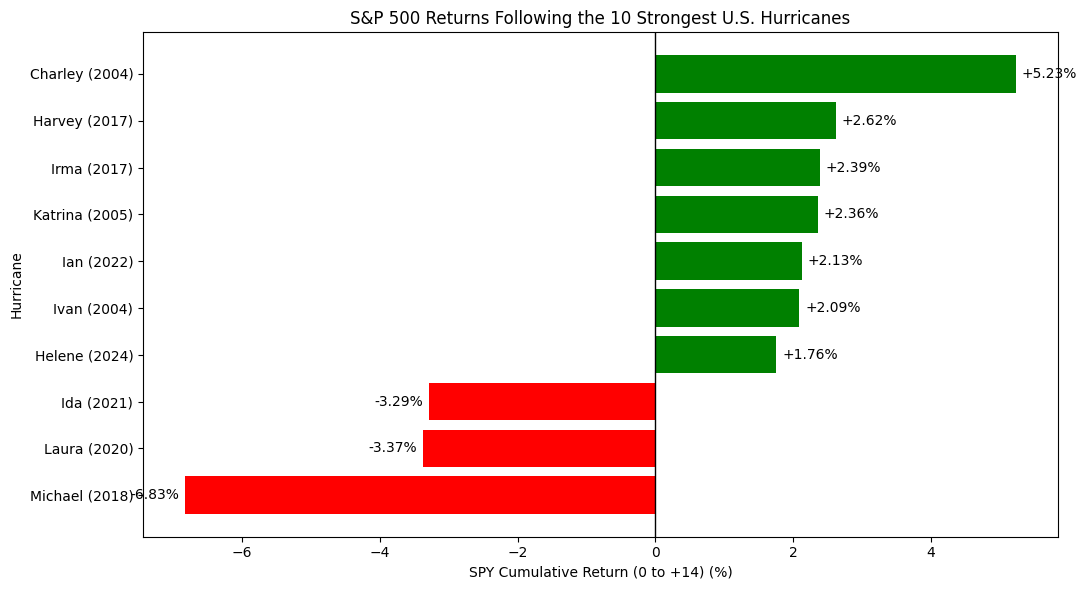

In [7]:
spy_14 = (
    spy_returns_df[
        spy_returns_df["window"] == "0_to_14"
    ]
    .sort_values("return_pct")
)

fig, ax = plt.subplots(figsize=(11, 6))

colors = np.where(
    spy_14["return_pct"] >= 0,
    "green",
    "red"
)

bars = ax.barh(
    spy_14["hurricane"],
    spy_14["return_pct"],
    color=colors
)

ax.axvline(0, color="black", linewidth=1)

ax.bar_label(
    bars,
    fmt="%+.2f%%",
    padding=4
)

ax.set_title(
    "S&P 500 Returns Following the 10 Strongest U.S. Hurricanes"
)

ax.set_xlabel("SPY Cumulative Return (0 to +14) (%)")
ax.set_ylabel("Hurricane")

plt.tight_layout()
plt.show()

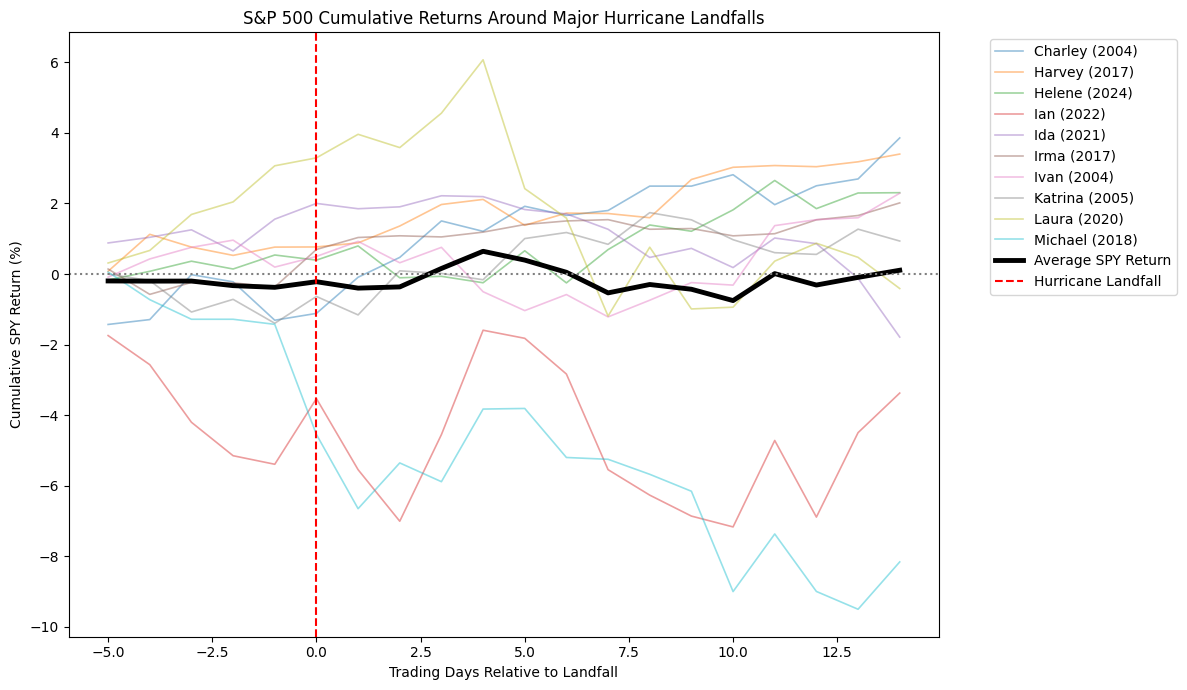

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))

for hurricane, group in spy_event_study.groupby("hurricane"):

    ax.plot(
        group["relative_day"],
        group["cumulative_return"],
        linewidth=1.2,
        alpha=0.45,
        label=hurricane
    )

average = (
    spy_event_study
    .groupby("relative_day")["cumulative_return"]
    .mean()
)

ax.plot(
    average.index,
    average.values,
    linewidth=3.5,
    color="black",
    label="Average SPY Return"
)

ax.axvline(
    0,
    color="red",
    linestyle="--",
    label="Hurricane Landfall"
)

ax.axhline(0, color="gray", linestyle=":")

ax.set_title(
    "S&P 500 Cumulative Returns Around Major Hurricane Landfalls"
)

ax.set_xlabel("Trading Days Relative to Landfall")
ax.set_ylabel("Cumulative SPY Return (%)")

ax.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [9]:
spy_summary = (
    spy_returns_df
    .groupby("window")
    .agg(
        mean_return=("return_pct", "mean"),
        median_return=("return_pct", "median"),
        positive_count=(
            "return_pct",
            lambda x: (x > 0).sum()
        ),
        negative_count=(
            "return_pct",
            lambda x: (x < 0).sum()
        ),
        total_storms=("return_pct", "count")
    )
    .reset_index()
)

display(spy_summary)

,window,mean_return,median_return,positive_count,negative_count,total_storms
0,0_to_1,-0.032195,0.273033,8,2,10
1,0_to_14,0.508820,2.111270,7,3,10
2,0_to_5,0.797998,0.441057,7,3,10


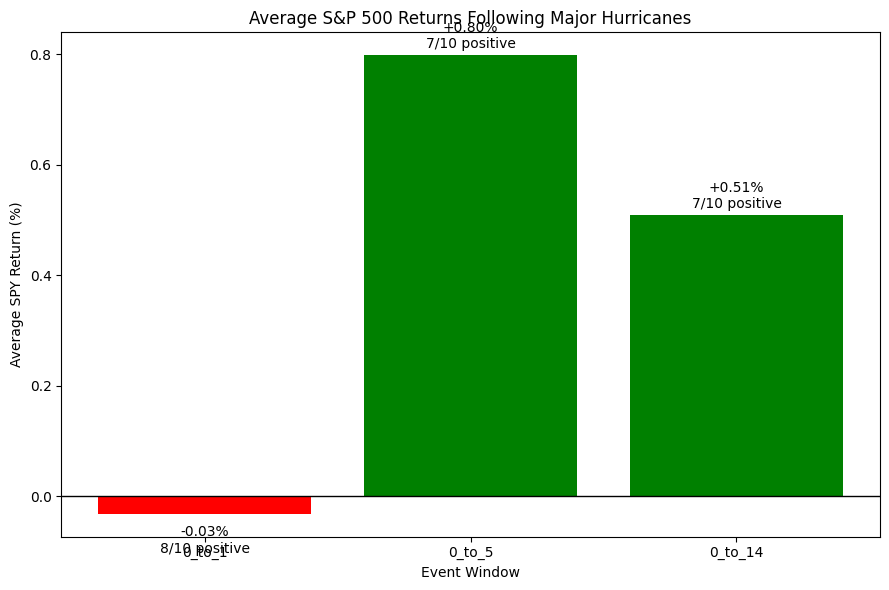

In [10]:
window_order = ["0_to_1", "0_to_5", "0_to_14"]

plot_data = (
    spy_summary
    .set_index("window")
    .loc[window_order]
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    plot_data["window"],
    plot_data["mean_return"],
    color=np.where(
        plot_data["mean_return"] >= 0,
        "green",
        "red"
    )
)

for bar, (_, row) in zip(bars, plot_data.iterrows()):

    ax.annotate(
        f"{row['mean_return']:+.2f}%\n"
        f"{int(row['positive_count'])}/{int(row['total_storms'])} positive",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(
            0,
            5 if bar.get_height() >= 0 else -28
        ),
        textcoords="offset points",
        ha="center"
    )

ax.axhline(0, color="black", linewidth=1)

ax.set_title(
    "Average S&P 500 Returns Following Major Hurricanes"
)

ax.set_xlabel("Event Window")
ax.set_ylabel("Average SPY Return (%)")

plt.tight_layout()
plt.show()

In [11]:
spy_without_2020 = (
    spy_returns_df[
        spy_returns_df["year"] != 2020
    ]
    .groupby("window")["return_pct"]
    .mean()
    .reset_index(name="mean_without_2020")
)

spy_comparison = spy_summary.merge(
    spy_without_2020,
    on="window",
    how="left"
)

display(spy_comparison[
    ["window", "mean_return", "mean_without_2020"]
])

,window,mean_return,mean_without_2020
0,0_to_1,-0.032195,-0.131994
1,0_to_14,0.508820,0.940345
2,0_to_5,0.797998,0.956355


In [12]:
significance_rows = []

for window_name, group in spy_returns_df.groupby("window"):

    values = group["return_pct"].dropna()

    if len(values) >= 2:
        t_stat, p_value = stats.ttest_1samp(
            values,
            popmean=0
        )
    else:
        t_stat, p_value = np.nan, np.nan

    significance_rows.append({
        "window": window_name,
        "mean_return": values.mean(),
        "n": len(values),
        "t_stat": t_stat,
        "p_value": p_value
    })

spy_significance = pd.DataFrame(significance_rows)

display(spy_significance.round(4))

,window,mean_return,n,t_stat,p_value
0,0_to_1,-0.0322,10,-0.0531,0.9588
1,0_to_14,0.5088,10,0.4338,0.6747
2,0_to_5,0.7980,10,1.2640,0.2380
